## **Gradient Descent Visualization**

Epoch 100/1000 - loss: 248.537757
Epoch 200/1000 - loss: 23.294162
Epoch 300/1000 - loss: 11.389096
Epoch 400/1000 - loss: 8.903066
Epoch 500/1000 - loss: 7.723732
Epoch 600/1000 - loss: 6.856508
Epoch 700/1000 - loss: 6.117031
Epoch 800/1000 - loss: 5.463619
Epoch 900/1000 - loss: 4.881801
Epoch 1000/1000 - loss: 4.362897

Trained parameters: m = [ 0.55416056  8.71080081 -8.4434956 ], b = 0.999000


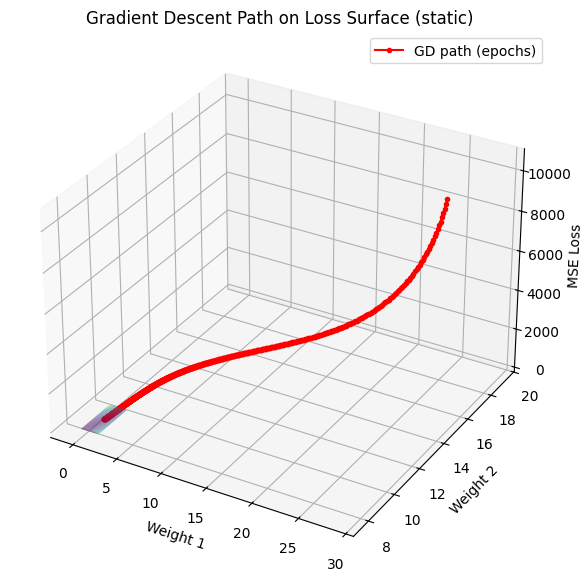

(4.172988482490922, 8.23119301719683)

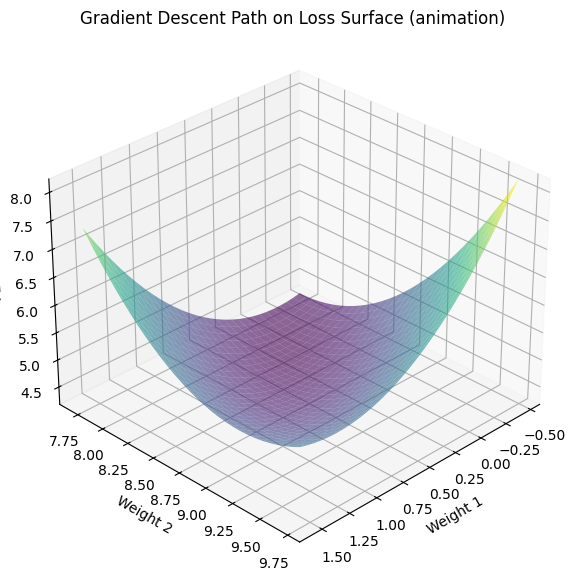

In [3]:
# JupyterLab-ready cell: 3D loss surface + animated GD path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D projection
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# ------------------------
# Create / scale 3D dataset
# ------------------------
np.random.seed(42)
X, Y = make_blobs(n_samples=1000, n_features=3, random_state=42)
Y = Y.reshape(-1, 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
y = Y.ravel()

# ------------------------
# Gradient Descent regressor (records history)
# ------------------------
class GDRegressor3D:
    def __init__(self, lr=0.01, epochs=1000, init_m=None, init_b=None):
        # allow user-specified initialization for reproducibility / experimentation
        if init_m is None:
            self.m = np.random.randn(3)
        else:
            self.m = np.asarray(init_m, dtype=float).copy()
        self.b = float(0.0 if init_b is None else init_b)
        self.lr = lr
        self.epochs = epochs
        self.history = []  # will store tuples (m_copy, b, loss)

    def fit(self, X, Y, verbose=True):
        X = np.asarray(X)
        y = np.asarray(Y).ravel()
        n_samples = X.shape[0]

        for i in range(self.epochs):
            preds = X.dot(self.m) + self.b
            error = y - preds

            grad_m = -2.0 / n_samples * X.T.dot(error)
            grad_b = -2.0 / n_samples * np.sum(error)

            self.m -= self.lr * grad_m
            self.b -= self.lr * grad_b

            loss = np.mean(error**2)
            # store history (copy weights)
            self.history.append((self.m.copy(), float(self.b), float(loss)))

            if verbose and (i+1) % (self.epochs // 10 or 1) == 0:
                print(f"Epoch {i+1}/{self.epochs} - loss: {loss:.6f}")

        return self.m, self.b

    def predict(self, X, m=None, b=None):
        X = np.asarray(X)
        if m is None: m = self.m
        if b is None: b = self.b
        return X.dot(m) + b

# ------------------------
# Train model (you can change lr / epochs)
# ------------------------
gd_model = GDRegressor3D(lr=0.01, epochs=1000, init_m=[29.19, 15.0, -10.0], init_b=-100.0)
gd_model.fit(X_scaled, Y, verbose=True)
print(f"\nTrained parameters: m = {gd_model.m}, b = {gd_model.b:.6f}")

# ------------------------
# Choose two weights to visualize (indices)
# ------------------------
f1_idx, f2_idx = 0, 1  # visualize weights m[0] vs m[1]
m_final = gd_model.m.copy()
b_final = gd_model.b

# ------------------------
# Build loss surface grid around final weights (expand range if needed)
# ------------------------
pad = 1.0  # how far around the final weights to sample
n_grid = 60
w1_min, w1_max = m_final[f1_idx] - pad, m_final[f1_idx] + pad
w2_min, w2_max = m_final[f2_idx] - pad, m_final[f2_idx] + pad
w1_range = np.linspace(w1_min, w1_max, n_grid)
w2_range = np.linspace(w2_min, w2_max, n_grid)
W1, W2 = np.meshgrid(w1_range, w2_range)
loss_surface = np.zeros_like(W1)

# compute MSE loss for each (w1,w2) while keeping other weights fixed
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        m_temp = m_final.copy()
        m_temp[f1_idx] = W1[i, j]
        m_temp[f2_idx] = W2[i, j]
        preds = X_scaled.dot(m_temp) + b_final
        loss_surface[i, j] = np.mean((y - preds) ** 2)

# ------------------------
# Extract GD path (w1, w2, loss)
# ------------------------
gd_path_w1 = [h[0][f1_idx] for h in gd_model.history]
gd_path_w2 = [h[0][f2_idx] for h in gd_model.history]
gd_path_loss = [h[2] for h in gd_model.history]

# ------------------------
# Static 3D plot (surface + final GD path)
# ------------------------
fig_static = plt.figure(figsize=(10, 7))
ax_static = fig_static.add_subplot(111, projection='3d')
ax_static.plot_surface(W1, W2, loss_surface, alpha=0.6, cmap='viridis', edgecolor='none', rcount=50, ccount=50)
ax_static.plot(gd_path_w1, gd_path_w2, gd_path_loss, color='red', marker='o', markersize=3, label='GD path (epochs)')
ax_static.set_xlabel(f'Weight {f1_idx+1}')
ax_static.set_ylabel(f'Weight {f2_idx+1}')
ax_static.set_zlabel('MSE Loss')
ax_static.set_title('Gradient Descent Path on Loss Surface (static)')
ax_static.legend()
plt.show()

# ------------------------
# Animated 3D plot: evolving path on top of static surface
# ------------------------
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Draw the static surface once
surf = ax.plot_surface(W1, W2, loss_surface, alpha=0.6, cmap='viridis', edgecolor='none', rcount=50, ccount=50)

# Prepare animated elements: a line and a point that move with epoch
line, = ax.plot([], [], [], color='red', linewidth=2, label='GD trajectory')
point, = ax.plot([], [], [], marker='o', color='black', markersize=6)

ax.set_xlabel(f'Weight {f1_idx+1}')
ax.set_ylabel(f'Weight {f2_idx+1}')
ax.set_zlabel('MSE Loss')
ax.set_title('Gradient Descent Path on Loss Surface (animation)')
ax.view_init(elev=30, azim=45)
ax.set_zlim(np.nanmin(loss_surface), np.nanmax(loss_surface))


## **Learning Visualization of Gradient Descent**

In [9]:
# JupyterLab-ready: 5D GD + loss-plane visualization (3D surface + 2D contour animation)
# Animates every 10th epoch: 1, 11, 21, ..., up to epochs (e.g. 2000)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from mpl_toolkits.mplot3d import Axes3D  # ensure 3D projection registered
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# ------------------------
# Data: 5D
# ------------------------
np.random.seed(42)
n_features = 5
X, Y = make_blobs(n_samples=1000, n_features=n_features, random_state=42)
Y = Y.reshape(-1, 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
y = Y.ravel()

# ------------------------
# GD regressor (records history)
# ------------------------
class GDRegressorND:
    def __init__(self, n_features, lr=0.01, epochs=100, init_m=None, init_b=0.0):
        self.n_features = n_features
        if init_m is None:
            self.m = np.random.randn(n_features).astype(float)
        else:
            self.m = np.asarray(init_m, dtype=float).copy()
        self.b = float(init_b)
        self.lr = float(lr)
        self.epochs = int(epochs)
        # history: list of tuples (m_copy, b, loss)
        self.history = []

    def fit(self, X, Y, verbose=True):
        X = np.asarray(X)
        y = np.asarray(Y).ravel()
        n_samples = X.shape[0]

        for epoch in range(self.epochs):
            preds = X.dot(self.m) + self.b
            error = y - preds

            grad_m = -2.0 / n_samples * X.T.dot(error)
            grad_b = -2.0 / n_samples * np.sum(error)

            self.m -= self.lr * grad_m
            self.b -= self.lr * grad_b

            loss = float(np.mean(error**2))
            self.history.append((self.m.copy(), float(self.b), loss))

            if verbose and (epoch+1) % (self.epochs // 10 or 1) == 0:
                print(f"Epoch {epoch+1}/{self.epochs} - loss: {loss:.6f}")

        return self.m, self.b

    def predict(self, X, m=None, b=None):
        X = np.asarray(X)
        if m is None: m = self.m
        if b is None: b = self.b
        return X.dot(m) + b

# ------------------------
# Train model (adjust lr/epochs as needed)
# ------------------------
epochs = 1000
gd_model = GDRegressorND(n_features=n_features, lr=0.01, epochs=epochs,
                         init_m=None, init_b=0.0)
gd_model.fit(X_scaled, Y, verbose=True)
print(f"\nTrained parameters: m = {gd_model.m}, b = {gd_model.b:.6f}")

# ------------------------
# Choose two features (weights) to visualize on the plane
# ------------------------
f1_idx, f2_idx = 0, 1  # indices of weights to visualize (0-based)
# Extract path of these weights + loss from history
gd_path_w1 = np.array([h[0][f1_idx] for h in gd_model.history])
gd_path_w2 = np.array([h[0][f2_idx] for h in gd_model.history])
gd_path_loss = np.array([h[2] for h in gd_model.history])

# Determine grid range to cover the path (with padding)
pad = 0.5
w1_min, w1_max = gd_path_w1.min() - pad, gd_path_w1.max() + pad
w2_min, w2_max = gd_path_w2.min() - pad, gd_path_w2.max() + pad

# Use the final model's other weights fixed for loss-surface computation
m_fixed = gd_model.m.copy()
b_fixed = gd_model.b

# Build grid
n_grid = 80
w1_range = np.linspace(w1_min, w1_max, n_grid)
w2_range = np.linspace(w2_min, w2_max, n_grid)
W1, W2 = np.meshgrid(w1_range, w2_range)
loss_surface = np.zeros_like(W1)

# Compute MSE loss for each (w1,w2) keeping other weights fixed at m_fixed
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        m_temp = m_fixed.copy()
        m_temp[f1_idx] = W1[i, j]
        m_temp[f2_idx] = W2[i, j]
        preds = X_scaled.dot(m_temp) + b_fixed
        loss_surface[i, j] = np.mean((y - preds) ** 2)

# ------------------------
# Set up figures: (A) 3D surface + path, (B) 2D contour (plane) + path
# ------------------------
fig = plt.figure(figsize=(16, 7))

# 3D Surface subplot
ax3d = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax3d.plot_surface(W1, W2, loss_surface, alpha=0.7, cmap='viridis', edgecolor='none', rcount=50, ccount=50)
ax3d.set_xlabel(f'Weight {f1_idx+1}')
ax3d.set_ylabel(f'Weight {f2_idx+1}')
ax3d.set_zlabel('MSE Loss')
ax3d.set_title('Loss surface (3D) and GD path')
ax3d.view_init(elev=30, azim=45)
ax3d.set_zlim(np.nanmin(loss_surface), np.nanmax(loss_surface))

# 2D contour subplot
ax2d = fig.add_subplot(1, 2, 2)
cont = ax2d.contourf(W1, W2, loss_surface, levels=50, cmap='viridis')
cbar = fig.colorbar(cont, ax=ax2d, shrink=0.8)
ax2d.set_xlabel(f'Weight {f1_idx+1}')
ax2d.set_ylabel(f'Weight {f2_idx+1}')
ax2d.set_title('Loss contours (plane) and GD path')

# Prepare animated artists (line + point) for both plots
line3d, = ax3d.plot([], [], [], color='red', linewidth=2, label='GD path (3D)')
point3d, = ax3d.plot([], [], [], marker='o', color='black', markersize=5)
line2d, = ax2d.plot([], [], color='red', linewidth=2, label='GD path (2D)')
point2d, = ax2d.plot([], [], marker='o', color='black', markersize=6)

ax2d.legend()
ax3d.legend()

# ------------------------
# Choose frame indices: every 10th epoch (0-based indices: 0,10,20,...)
# ------------------------
step = 20
frame_indices = np.arange(0, len(gd_model.history), step)
# ensure last epoch included (in case len-1 not divisible by step)
if frame_indices[-1] != len(gd_model.history) - 1:
    frame_indices = np.append(frame_indices, len(gd_model.history) - 1)

# ------------------------
# Animation update function
# ------------------------
def update(epoch_idx):
    # epoch_idx is actual epoch index (0-based) from frame_indices
    xs = gd_path_w1[:epoch_idx+1]
    ys = gd_path_w2[:epoch_idx+1]
    zs = gd_path_loss[:epoch_idx+1]

    # update 3D line + point
    line3d.set_data(xs, ys)
    line3d.set_3d_properties(zs)
    point3d.set_data([float(xs[-1])], [float(ys[-1])])
    point3d.set_3d_properties([float(zs[-1])])

    # update 2D line + point
    line2d.set_data(xs, ys)
    point2d.set_data([float(xs[-1])], [float(ys[-1])])

    # update titles to reflect displayed epoch (human-friendly 1-based)
    displayed_epoch = epoch_idx + 1
    ax3d.set_title(f'Loss surface (3D) - epoch {displayed_epoch}/{len(gd_model.history)} - loss {float(zs[-1]):.6f}')
    ax2d.set_title(f'Loss contours (plane) - epoch {displayed_epoch}/{len(gd_model.history)} - loss {float(zs[-1]):.6f}')

    return (line3d, point3d, line2d, point2d)

# Create animation using selected frame_indices
interval = 80  # ms between frames (tweak for speed)
anim = FuncAnimation(fig, update, frames=frame_indices, interval=interval, blit=False)

# Close static figure display (we will embed the animation)
plt.close(fig)

# Display interactive HTML animation in JupyterLab
HTML(anim.to_jshtml())


Epoch 100/1000 - loss: 0.234841
Epoch 200/1000 - loss: 0.108723
Epoch 300/1000 - loss: 0.073449
Epoch 400/1000 - loss: 0.059033
Epoch 500/1000 - loss: 0.051382
Epoch 600/1000 - loss: 0.046523
Epoch 700/1000 - loss: 0.043149
Epoch 800/1000 - loss: 0.040718
Epoch 900/1000 - loss: 0.038943
Epoch 1000/1000 - loss: 0.037639

Trained parameters: m = [-0.50936447 -0.08344791  0.06632934 -0.31752463 -0.03749501], b = 0.999000
